# Part A: Dataset Loading. #

In [ ]:
#-- Import Libraries. --#
import os
from google.colab import drive
#-- Mount Google Drive --#
drive.mount('/content/drive')
#-- Import Dataset through Google Drive. --#
data_directory = '/content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab05 - Transfer Learning/'
train_directory = os.path.join(data_directory, 'train')
test_directory = os.path.join(data_directory, 'test')
#-- Print Confirmation. --#
print(f"Train Directory: {train_directory}")
print(f"Test Directory: {test_directory}")

Mounted at /content/drive
Train Directory: /content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab05 - Transfer Learning/train
Test Directory: /content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab05 - Transfer Learning/test


In [ ]:
#-- Check Direcotry Exists or Not. --#
if os.path.exists(data_directory):
    print(f"{train_directory} exists")
    if os.path.exists(train_directory):
        print(f"{train_directory} exists")
    else:
        print(f"{train_directory} does not exist")
else:
    print(f"{train_directory} does not exist")

/content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab05 - Transfer Learning/train exists
/content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab05 - Transfer Learning/train exists


In [ ]:
#-- Figure out what is inside the train_directory. --#
print(f"List of sub-folders in the {train_directory}:")
classes = os.listdir(train_directory)
print(classes)
#-- Total number of classes. --#
print(f"Total number of classes: {len(classes)}")
#-- Count each image in the class. --#
print("Number of each image in per class:")
for class_name in sorted(classes):
  class_path = os.path.join(train_directory, class_name)
  if os.path.isdir(class_path):
    num_images = len(os.listdir(class_path))
    print(f"- {class_name}: {num_images} classes")

List of sub-folders in the /content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab05 - Transfer Learning/train:
['Animalia', 'Fungi', 'Amphibia', 'Reptilia', 'Aves', 'Plantae', 'Arachnida', 'Mammalia', 'Insecta', 'Mollusca']
Total number of classes: 10
Number of each image in per class:
- Amphibia: 491 classes
- Animalia: 509 classes
- Arachnida: 500 classes
- Aves: 511 classes
- Fungi: 493 classes
- Insecta: 509 classes
- Mammalia: 498 classes
- Mollusca: 509 classes
- Plantae: 517 classes
- Reptilia: 499 classes


In [ ]:
#-- Check test_train folder exists or not. --#
if os.path.exists(test_directory): #-- Exists condition. --#
  test_files = os.listdir(test_directory)
  print(f"The directory {test_directory} exists and has {len(test_files)} images.")
else: #-- Does not exist condition. --#
  print(f"The directory {test_directory} does not exist. Please check again.")

The directory /content/drive/MyDrive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab05 - Transfer Learning/test exists and has 2000 images.


In [ ]:
#-- Import Python Library. --#
import tensorflow as tf
#-- Training Dataset. --#
training_dataset = tf.keras.utils.image_dataset_from_directory(train_directory, validation_split=0.2, subset="training", seed=123)
#-- Validation Dataset. --#
validation_dataset = tf.keras.utils.image_dataset_from_directory(train_directory, validation_split=0.2, subset="validation", seed=123)
#-- Test Dataset. --#
test_dataset = tf.keras.utils.image_dataset_from_directory(test_directory, label_mode=None, shuffle=False)

Found 5036 files belonging to 10 classes.
Using 4029 files for training.
Found 5036 files belonging to 10 classes.
Using 1007 files for validation.
Found 2000 files.


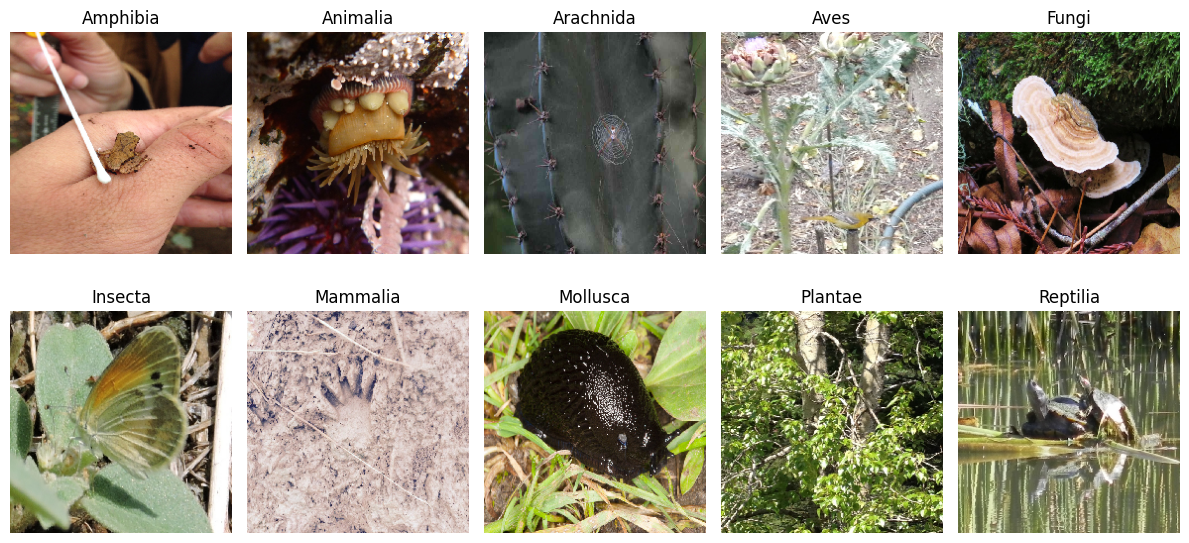

In [ ]:
#-- Import Library. --#
import os
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array
class_names = training_dataset.class_names
plt.figure(figsize=(12, 6))
for i, class_name in enumerate(class_names):
  class_path = os.path.join(train_directory, class_name)
  #-- Take the first file of each sub-class. --#
  img_files = os.listdir(class_path)
  if img_files:
    img_path = os.path.join(class_path, img_files[0])
    img = load_img(img_path, target_size=(224, 224))
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis('off')
#-- Shows image. --#
plt.tight_layout()
plt.show()

# Part B. Exploratory Data Analysis (EDA). #

## 2.1 Check Class Distribution. ##

In [ ]:
#-- Take class list from folder train_directory. --#
class_names = sorted(os.listdir(train_directory))
class_counts = {}
#- Count total of images in each class. 00#
for class_name in class_names:
  class_path = os.path.join(train_directory, class_name)
  if os.path.isdir(class_path):
    num_images = len(os.listdir(class_path))
    class_counts[class_name] = num_images
    print(f"- {class_name}: {num_images} images")

- Amphibia: 491 images
- Animalia: 509 images
- Arachnida: 500 images
- Aves: 511 images
- Fungi: 493 images
- Insecta: 509 images
- Mammalia: 498 images
- Mollusca: 509 images
- Plantae: 517 images
- Reptilia: 499 images


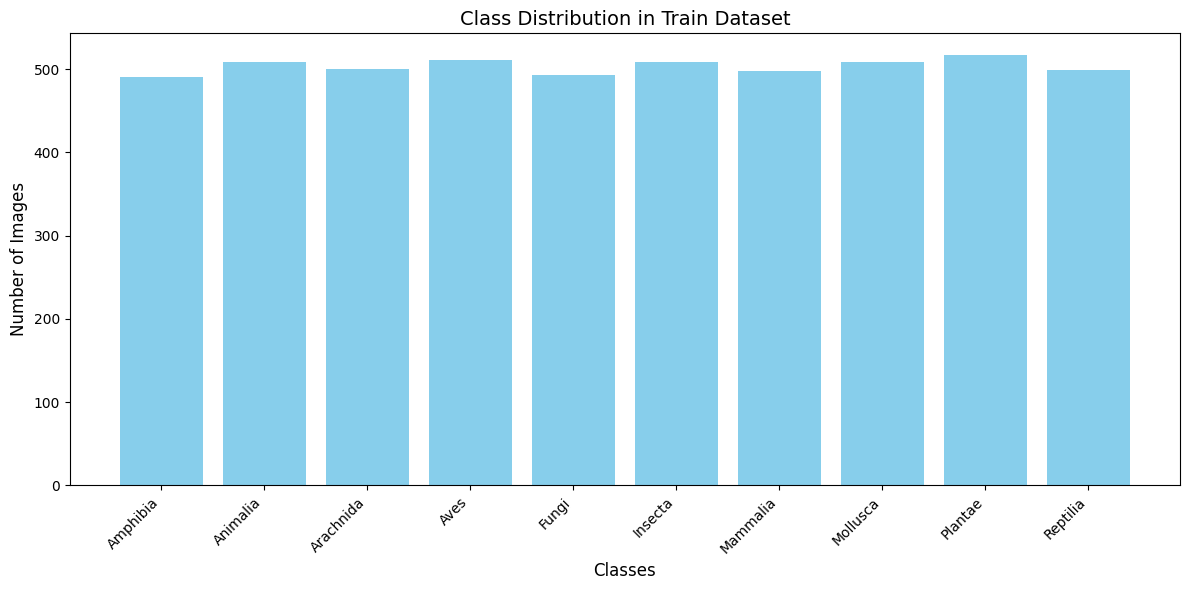

In [ ]:
#-- Visualizae. --#
plt.figure(figsize=(12, 6))
plt.bar(class_counts.keys(), class_counts.values(), color='skyblue')
plt.xlabel('Classes', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.title('Class Distribution in Train Dataset', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 2.2 Check Image Dimension, Pixel Range, and Colour Channel. ##

In [ ]:
#-- Import Library. --#
from PIL import Image
#-- Check the dimensions of a few sample images across classes. --#
image_sizes = []
class_names = sorted(os.listdir(train_directory))
for class_name in class_names:
  class_path = os.path.join(train_directory, class_name)
  if os.path.isdir(class_path):
    img_files = os.listdir(class_path)
    # Check the first few images of each class
    for img_file in img_files[:5]:
      img_path = os.path.join(class_path, img_file)
      try:
        with Image.open(img_path) as img:
          image_sizes.append(img.size)  # (width, height)
      except Exception:
        pass
#-- Print out unique image sizes found in the dataset. --#
unique_sizes = set(image_sizes)
print(f"Unique image dimensions found in the dataset: {unique_sizes}")

Unique image dimensions found in the dataset: {(800, 614), (800, 641), (800, 534), (705, 800), (800, 598), (597, 800), (800, 601), (533, 800), (800, 692), (800, 533), (800, 594), (800, 600), (704, 800), (451, 800), (800, 682), (800, 386), (631, 800), (534, 800), (600, 800), (785, 800), (666, 800), (800, 770), (800, 535), (800, 773), (800, 532), (800, 538)}


In [ ]:
#-- Check the color modes (e.g., RGB, RGBA, L - Grayscale) of sample images. --#
color_modes = set()
class_names = sorted(os.listdir(train_directory))
for class_name in class_names:
  class_path = os.path.join(train_directory, class_name)
  if os.path.isdir(class_path):
    img_files = os.listdir(class_path)
    #-- Check the first few images of each class. --#
    for img_file in img_files[:5]:
      img_path = os.path.join(class_path, img_file)
      try:
        with Image.open(img_path) as img:
          color_modes.add(img.mode)
      except Exception:
        pass
print(f"Color modes found in the dataset: {color_modes}")

Color modes found in the dataset: {'RGB'}


In [ ]:
import os
import numpy as np
from PIL import Image

pixel_mins = []
pixel_maxs = []

# Use os.walk to recursively scan all image files inside the subdirectories of train_directory
for root, dirs, files in os.walk(train_directory):
  for img_file in files:
    # Filter for common image formats
    if img_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
      img_path = os.path.join(root, img_file)
      try:
        with Image.open(img_path) as img:
          img_array = np.array(img)
          pixel_mins.append(img_array.min())
          pixel_maxs.append(img_array.max())
      except Exception:
        pass

# Check if the list is not empty before printing results
if pixel_mins:
  print(f'Minimum pixel value in the dataset: {min(pixel_mins)}')
  print(f'Maximum pixel value in the dataset: {max(pixel_maxs)}')
else:
  print('No image files found in the specified directory!')

Minimum pixel value in the dataset: 0
Maximum pixel value in the dataset: 255


# Part C: Data Processing. #

## 3.1 Resize Image. ##

In [ ]:
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32
#-- Resize Train dataset (80%). --#
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_directory,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
)
#-- Resize validation dataset (20%). --#
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_directory,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
)

Found 5036 files belonging to 10 classes.
Using 4029 files for training.
Found 5036 files belonging to 10 classes.
Using 1007 files for validation.


In [ ]:
#-- Test dataset (Loaded from separate test directory without label subfolders). --#
test_image_paths = []
for root, dirs, files in os.walk(test_directory):
  for file in files:
    if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
      test_image_paths.append(os.path.join(root, file))
print(f'Found {len(test_image_paths)} images in the test directory.')
#-- Helper function to load, decode, and resize test images. --#
def load_and_resize_test_image(path):
  image = tf.io.read_file(path)
  image = tf.image.decode_image(image, channels=3, expand_animations=False)
  image.set_shape([None, None, 3])  # Ensure static channel dimension
  image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
  return image
# Build the test dataset pipeline
test_dataset = tf.data.Dataset.from_tensor_slices(test_image_paths)
test_dataset = test_dataset.map(
    load_and_resize_test_image, num_parallel_calls=tf.data.AUTOTUNE
)
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Found 2000 images in the test directory.


## 3.2 Pixel re-format please. ##

In [ ]:
#-- Normalize Train and Validation datasets (which contain (image, label) tuples). --#
normalization_layer = lambda x, y: (x / 255.0, y)
train_dataset = train_dataset.map(
    normalization_layer, num_parallel_calls=tf.data.AUTOTUNE
)
validation_dataset = validation_dataset.map(
    normalization_layer, num_parallel_calls=tf.data.AUTOTUNE
)
#-- Normalize Test dataset (which only contains images, no labels). --#
test_dataset = test_dataset.map(
    lambda x: x / 255.0, num_parallel_calls=tf.data.AUTOTUNE
)
#-- Performance Optimization with .cache() and .prefetch(). --#
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)
print('Pixel normalization and performance optimization completed!')

Pixel normalization and performance optimization completed!


## 3.3 Data Augumentation. ##

In [ ]:
#-- Define the data augmentation sequence. --#
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),  # Random horizontal flip
    tf.keras.layers.RandomRotation(0.1),  # Random rotation by 10%
    tf.keras.layers.RandomZoom(0.1),  # Random zoom in/out by 10%
])
#-- Apply augmentation ONLY to the training dataset. --#
# Note: setting training=True ensures the random effects are active
train_dataset = train_dataset.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE,
)
print('Data Augmentation successfully added to the training pipeline (Train only)!')

Data Augmentation successfully added to the training pipeline (Train only)!


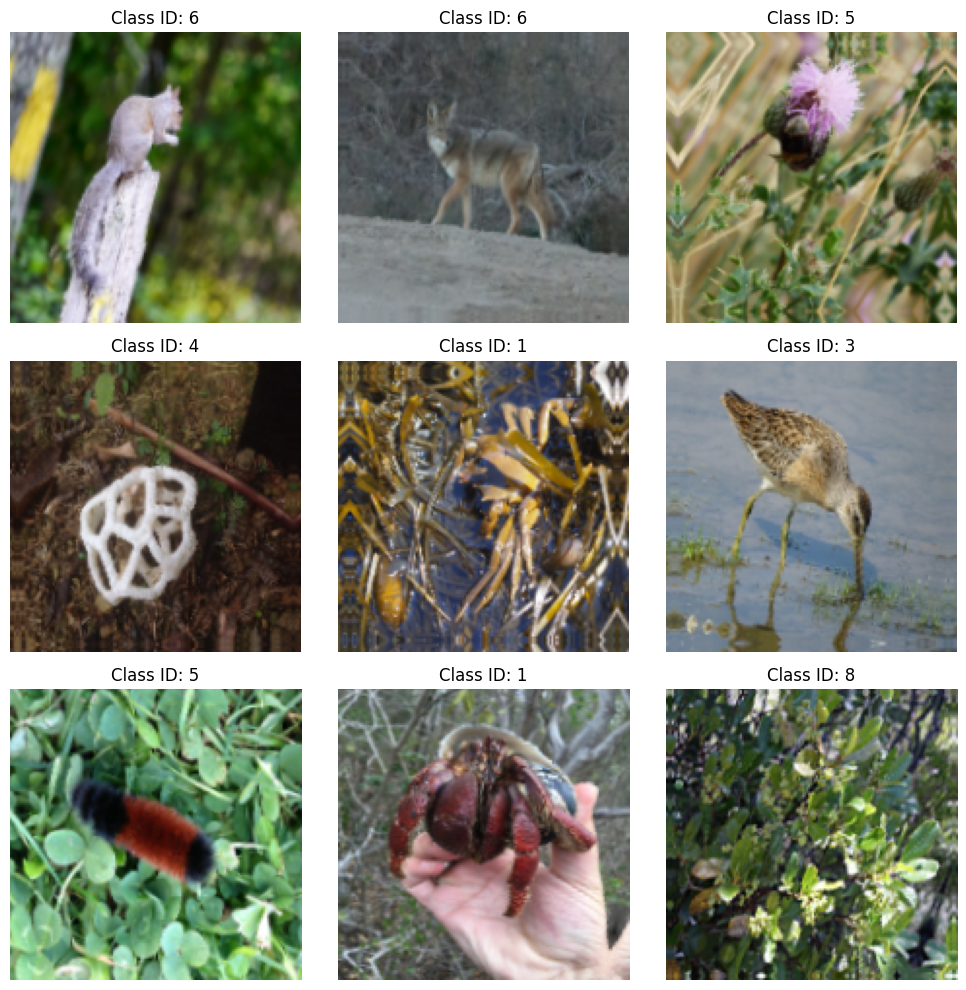

In [ ]:
import matplotlib.pyplot as plt

# Take one batch from your training dataset
for images, labels in train_dataset.take(1):
  plt.figure(figsize=(10, 10))

  # Plot the first 9 images from the batch
  for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)

    # Convert tensor to numpy array for display
    plt.imshow(images[i].numpy())

    # Display the label index (or class name if you have class_names defined)
    plt.title(f'Class ID: {labels[i].numpy()}')
    plt.axis('off')

  plt.tight_layout()
  plt.show()
  break

# Part D: Model Building and Training. #

## 4.1 MobileNetV2 Model. ##

In [ ]:
#-- Configure Early Stopping and Model Checkpoint. --#
callbacks = [
    #-- start_from_epoch=10: Ensures training runs for at least 10 epochs before early stopping kicks in. --#
    #-- patience=5: Stops training if val_accuracy does not improve for 10 consecutive epochs. --#
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        start_from_epoch=10,
        restore_best_weights=True,
        verbose=1,
    ),
    #-- Automatically save the best model checkpoint file. --#
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_mobilenet_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1,
    ),
]
print("Callbacks configured successfully!")

Callbacks configured successfully!


In [ ]:
#-- Load base MobileNetV2, excluding the top classification layers. -#
base_model_mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(150, 150, 3), include_top=False, weights='imagenet'
)
#-- PHASE 1: Freeze the entire base model to preserve ImageNet weights. --#
base_model_mobilenet.trainable = False
#-- Build the complete architecture for Phase 1. --#
model_mobilenet = tf.keras.Sequential(
    [
        base_model_mobilenet,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.2),  # Mild dropout for the warm-up phase
        tf.keras.layers.Dense(10, activation='softmax'),  # 10 classes
    ]
)
#-- Compile the model with a standard learning rate. --#
model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)
model_mobilenet.summary()

/tmp/ipykernel_537/1665252757.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_mobilenet = tf.keras.applications.MobileNetV2(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
#-- Start Phase 1 training. --#
EPOCHS_PHASE_1 = 50
history_phase1 = model_mobilenet.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_PHASE_1,
    callbacks=callbacks,
)

Epoch 1/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.2478 - loss: 2.3662
Epoch 1: val_accuracy improved from None to 0.50546, saving model to best_mobilenet_model.keras

Epoch 1: finished saving model to best_mobilenet_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 33s 200ms/step - accuracy: 0.3318 - loss: 2.0164 - val_accuracy: 0.5055 - val_loss: 1.4491
Epoch 2/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.4699 - loss: 1.5217
Epoch 2: val_accuracy improved from 0.50546 to 0.54121, saving model to best_mobilenet_model.keras

Epoch 2: finished saving model to best_mobilenet_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 16s 125ms/step - accuracy: 0.4808 - loss: 1.5126 - val_accuracy: 0.5412 - val_loss: 1.3809
Epoch 3/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.5299 - loss: 1.3851
Epoch 3: val_accuracy did not improve from 0.54121
126/126 ━━━━━━━━━━━━━━━━━━━━ 20s 119ms/step - accuracy: 0.5240 - loss: 1.3884 - val_accuracy: 0.5293 - val_loss: 1.3973
Epoch 

In [ ]:
#-- Unfreeze the base model for deep fine-tuning. --#
base_model_mobilenet.trainable = True
#-- Re-compile the model with a TINY Learning Rate to protect pre-trained weights. --#
model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),  #-- Tiny LR for fine-tuning. --#
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)
model_mobilenet.summary()
#-- Train Phase 2 (Allow it to run long-term; EarlyStopping and Checkpoint handle the cut-off). --#
EPOCHS_PHASE_2 = 100
history_phase2 = model_mobilenet.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_PHASE_2,
    callbacks=callbacks,
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 2,236,682 (8.53 MB)

 Non-trainable params: 34,112 (133.25 KB)

Epoch 1/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.4769 - loss: 1.6339
Epoch 1: val_accuracy did not improve from 0.54916
126/126 ━━━━━━━━━━━━━━━━━━━━ 82s 331ms/step - accuracy: 0.4860 - loss: 1.5814 - val_accuracy: 0.5422 - val_loss: 1.4541
Epoch 2/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.5500 - loss: 1.3595
Epoch 2: val_accuracy did not improve from 0.54916
126/126 ━━━━━━━━━━━━━━━━━━━━ 17s 130ms/step - accuracy: 0.5505 - loss: 1.3500 - val_accuracy: 0.5422 - val_loss: 1.4849
Epoch 3/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.5779 - loss: 1.2695
Epoch 3: val_accuracy did not improve from 0.54916
126/126 ━━━━━━━━━━━━━━━━━━━━ 17s 130ms/step - accuracy: 0.5786 - loss: 1.2622 - val_accuracy: 0.5422 - val_loss: 1.4745
Epoch 4/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.6024 - loss: 1.1598
Epoch 4: val_accuracy did not improve from 0.54916
126/126 ━━━━━━━━━━━━━━━━━━━━ 20s 129ms/step - accuracy: 0.5969 - loss: 1.1671 - 

In [ ]:
print("Generating predictions on the unlabeled test dataset...")
best_model = tf.keras.models.load_model("best_mobilenet_model.keras")

#-- Use predict since there are no labels in test_dataset --#
predictions = best_model.predict(test_dataset)
predicted_classes = np.argmax(predictions, axis=1)

print(f"\n============================")
print(f"Successfully predicted classes for {len(predicted_classes)} test images.")
print(f"First 10 predicted class indices: {predicted_classes[:10]}")
print(f"Map to names: {[class_names[idx] for idx in predicted_classes[:10]]}")
print(f"============================")

Generating predictions on the unlabeled test dataset...
63/63 ━━━━━━━━━━━━━━━━━━━━ 477s 8s/step

Successfully predicted classes for 2000 test images.
First 10 predicted class indices: [7 7 8 9 1 9 9 1 9 7]
Map to names: ['Mollusca', 'Mollusca', 'Plantae', 'Reptilia', 'Animalia', 'Reptilia', 'Reptilia', 'Animalia', 'Reptilia', 'Mollusca']


In [ ]:
print("Evaluate on Validation Dataset...")
best_model = tf.keras.models.load_model("best_mobilenet_model.keras")
val_loss, val_accuracy = best_model.evaluate(validation_dataset)
print(f"\n============================")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"============================")

Evaluate on Validation Dataset...
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.5730 - loss: 1.4208

Validation Accuracy: 57.30%
Validation Loss: 1.4208


## 4.2 EfficientNetB0 (EfficientNetV2B0) Model. ##

In [ ]:
#-- Load base EfficientNetB0, excluding the top classification layers. --#
base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(150, 150, 3), include_top=False, weights='imagenet'
)
#-- PHASE 1: Freeze the entire base model to preserve ImageNet weights. --#
base_model.trainable = False
#-- Build the complete architecture for Phase 1. --#
model_efficientnet = tf.keras.Sequential(
    [
        base_model,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.2),  # Mild dropout for the warm-up phase
        tf.keras.layers.Dense(10, activation='softmax'),  # 10 classes
    ]
)
#-- Compile the model with a standard learning rate. --#
model_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)
model_efficientnet.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 5, 5, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
#-- Configure callbacks to save the best model under a unique name. --#
callbacks_eff = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        start_from_epoch=10,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_efficientnet_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1,
    ),
]
#-- Start Phase 1 training. --#
EPOCHS_PHASE_1 = 50

history_eff_phase1 = model_efficientnet.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_PHASE_1,
    callbacks=callbacks_eff,
)

Epoch 1/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.0936 - loss: 2.3508
Epoch 1: val_accuracy improved from None to 0.10427, saving model to best_efficientnet_model.keras

Epoch 1: finished saving model to best_efficientnet_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 70s 349ms/step - accuracy: 0.1010 - loss: 2.3407 - val_accuracy: 0.1043 - val_loss: 2.3236
Epoch 2/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.0986 - loss: 2.3390
Epoch 2: val_accuracy did not improve from 0.10427
126/126 ━━━━━━━━━━━━━━━━━━━━ 16s 124ms/step - accuracy: 0.1028 - loss: 2.3348 - val_accuracy: 0.1043 - val_loss: 2.3212
Epoch 3/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.1074 - loss: 2.3347
Epoch 3: val_accuracy did not improve from 0.10427
126/126 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.1047 - loss: 2.3328 - val_accuracy: 0.1043 - val_loss: 2.3212
Epoch 4/50
125/126 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.1015 - loss: 2.3269
Epoch 4: val_accuracy 

In [ ]:
#-- Unfreeze the base model for deep fine-tuning. --#
base_model.trainable = True
#-- Re-compile the model with a TINY Learning Rate to protect pre-trained weights. --#
model_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),  #-- Tiny LR for fine-tuning. --#
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)
model_efficientnet.summary()
#-- Train Phase 2 with a longer epoch schedule. --#
EPOCHS_PHASE_2 = 100

history_eff_phase2 = model_efficientnet.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_PHASE_2,
    callbacks=callbacks_eff,
)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 5, 5, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 4,020,358 (15.34 MB)

 Non-trainable params: 42,023 (164.16 KB)

Epoch 1/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 554ms/step - accuracy: 0.1068 - loss: 2.4362
Epoch 1: val_accuracy did not improve from 0.10626
126/126 ━━━━━━━━━━━━━━━━━━━━ 166s 649ms/step - accuracy: 0.1204 - loss: 2.4124 - val_accuracy: 0.0904 - val_loss: 2.3450
Epoch 2/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.1661 - loss: 2.2934
Epoch 2: val_accuracy did not improve from 0.10626
126/126 ━━━━━━━━━━━━━━━━━━━━ 24s 135ms/step - accuracy: 0.1720 - loss: 2.2842 - val_accuracy: 0.0963 - val_loss: 2.3454
Epoch 3/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.2058 - loss: 2.1984
Epoch 3: val_accuracy did not improve from 0.10626
126/126 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step - accuracy: 0.2139 - loss: 2.1880 - val_accuracy: 0.0924 - val_loss: 2.3800
Epoch 4/100
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.2440 - loss: 2.1120
Epoch 4: val_accuracy improved from 0.10626 to 0.14995, saving model to best_efficientnet_model.keras

Epoch 4: finished saving mo

In [ ]:
import numpy as np
import tensorflow as tf

# 1. Tải mô hình EfficientNet tốt nhất
print("Loading model EfficientNetB0...")
best_eff_model = tf.keras.models.load_model("best_efficientnet_model.keras")

# 2. Đánh giá độ chính xác (Accuracy) trên tập dữ liệu Validation có nhãn
val_loss, val_accuracy = best_eff_model.evaluate(validation_dataset, verbose=0)

# 3. Dự đoán trên tập test (Unlabeled test dataset)
print("Đang chạy dự đoán trên tập test...")
predictions = best_eff_model.predict(test_dataset)
predicted_classes = np.argmax(predictions, axis=1)

print(f"\n============================")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Predicted label successful {len(predicted_classes)} images in test dataset!")
print(f"============================")

Loading model EfficientNetB0...
Đang chạy dự đoán trên tập test...
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 309ms/step

Validation Accuracy: 58.69%
Predicted label successful 2000 images in test dataset!


Predcition...
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 181ms/step

Estimated Accurancy: 63.82%
Validation Accuracy: 58.69%



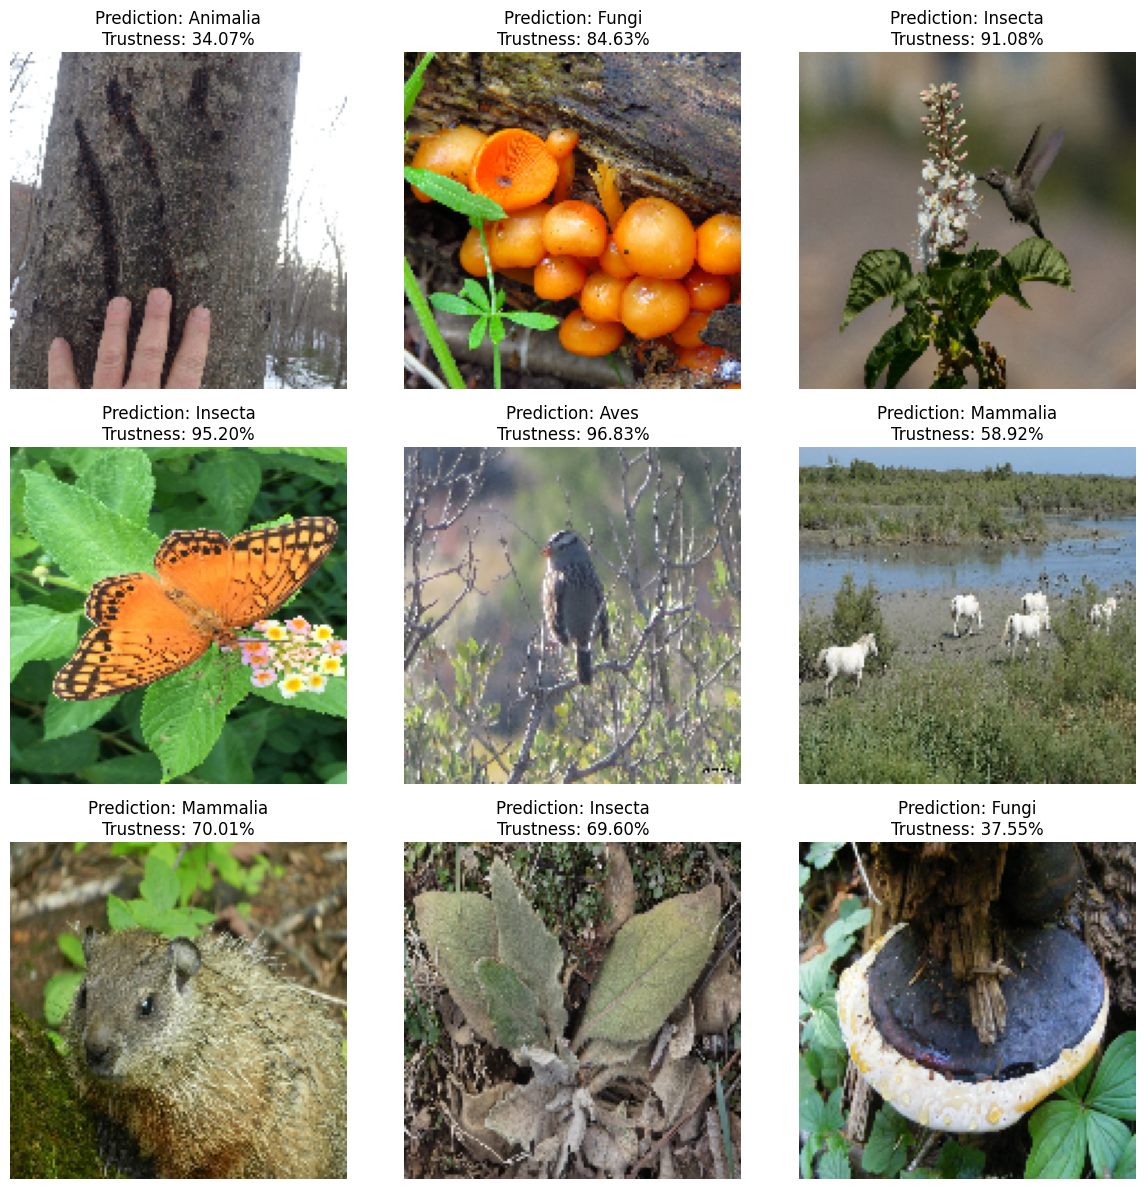

In [ ]:
print("Predcition...")
predictions = best_eff_model.predict(test_dataset)
predicted_classes = np.argmax(predictions, axis=1)
estimated_accuracy = np.mean(np.max(predictions, axis=1)) * 100

print(f"\n============================")
print(f"Estimated Accurancy: {estimated_accuracy:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"============================\n")

plt.figure(figsize=(12, 12))
for i in range(9):
    idx = np.random.randint(0, len(test_image_paths))
    img_path = test_image_paths[idx]
    img = tf.keras.utils.load_img(img_path, target_size=(IMG_HEIGHT, IMG_WIDTH))

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)

    pred_label = class_names[predicted_classes[idx]]
    confidence = np.max(predictions[idx]) * 100

    plt.title(f"Prediction: {pred_label}\nTrustness: {confidence:.2f}%")
    plt.axis('off')

plt.tight_layout()
plt.show()

## 4.3 ConvNeXtTiny Model. ##

In [ ]:
#-- 1. Load base ConvNeXtTiny from Keras Applications, excluding the top classification layers. --#
base_model_convnext = tf.keras.applications.ConvNeXtTiny(
    input_shape=(150, 150, 3), include_top=False, weights='imagenet'
)
#-- PHASE 1: Freeze the entire base model to preserve ImageNet weights. --#
base_model_convnext.trainable = False
#-- 2. Build the complete architecture for Phase 1. --#
model_convnext = tf.keras.Sequential(
    [
        base_model_convnext,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.2),  # Mild dropout for the warm-up phase
        tf.keras.layers.Dense(10, activation='softmax'),  # 10 classes
    ]
)
#-- 3. Compile the model with a standard learning rate. --#
model_convnext.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)
model_convnext.summary()

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ convnext_tiny (Functional)      │ (None, 4, 4, 768)      │    27,820,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 768)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         7,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,827,818 (106.15 MB)

 Trainable params: 7,690 (30.04 KB)

 Non-trainable params: 27,820,128 (106.13 MB)

In [ ]:
#-- Configure callbacks to save the best model under a unique name. --#
callbacks_convnext = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        start_from_epoch=10,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_convnext_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1,
    ),
]
#-- Start Phase 1 training. --#
EPOCHS_PHASE_1 = 50

history_convnext_phase1 = model_convnext.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_PHASE_1,
    callbacks=callbacks_convnext,
)

Epoch 1/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.1244 - loss: 2.4679
Epoch 1: val_accuracy improved from None to 0.20953, saving model to best_convnext_model.keras

Epoch 1: finished saving model to best_convnext_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 54s 298ms/step - accuracy: 0.1392 - loss: 2.3773 - val_accuracy: 0.2095 - val_loss: 2.2130
Epoch 2/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.1816 - loss: 2.2300
Epoch 2: val_accuracy improved from 0.20953 to 0.24032, saving model to best_convnext_model.keras

Epoch 2: finished saving model to best_convnext_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 19s 147ms/step - accuracy: 0.1894 - loss: 2.2157 - val_accuracy: 0.2403 - val_loss: 2.1603
Epoch 3/50
125/126 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.2089 - loss: 2.1756
Epoch 3: val_accuracy improved from 0.24032 to 0.26514, saving model to best_convnext_model.keras

Epoch 3: finished saving model to best_convnext_model.keras
126/126 ━━━━━━━━━━━━━━

In [ ]:
#-- Unfreeze the base model for deep fine-tuning. --#
base_model_convnext.trainable = True
#-- Re-compile the model with a TINY Learning Rate to protect pre-trained weights. --#
model_convnext.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),  # Tiny LR for fine-tuning
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)
model_convnext.summary()
#-- Train Phase 2 with a longer epoch schedule. --#
EPOCHS_PHASE_2 = 100

history_convnext_phase2 = model_convnext.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_PHASE_2,
    callbacks=callbacks_convnext,
)

NameError: name 'base_model_convnext' is not defined

# Part E: Performance Comparison (Feature Extraction vs Fine-Tuning). #

Compare the two transfer-learning approaches required by the lab for every pre-trained backbone trained above:

* **Feature Extraction (FE):** base model frozen, only `GlobalAveragePooling2D -> Dropout -> Dense(10)` trained (`lr = 1e-3`).
* **Fine-Tuning (FT):** base model unfrozen, whole network trained further (`lr = 1e-5`).

All numbers below are copied from the training logs of Part D (best `val_accuracy` restored by `EarlyStopping`; training time = sum of the per-epoch times printed by Keras on the Colab T4 GPU). The test folder has no labels, so **validation accuracy** is the metric used for the comparison.

## 5.1 Results table. ##

In [2]:
#-- Recorded results (copied from the Part D training logs). --#
import pandas as pd

RESULTS = {
    #-- model: {approach: {metrics}} --#
    "MobileNetV2": {
        "Feature Extraction": dict(val_acc=0.5492, train_acc=0.6128, epochs=23, best_epoch=13, time_s=409, trainable=12_810),
        "Fine-Tuning":        dict(val_acc=0.5730, train_acc=0.7156, epochs=22, best_epoch=12, time_s=470, trainable=2_236_682),
    },
    "EfficientNetB0": {
        "Feature Extraction": dict(val_acc=0.1063, train_acc=0.1092, epochs=18, best_epoch=13, time_s=386, trainable=12_810),
        "Fine-Tuning":        dict(val_acc=0.5869, train_acc=0.7466, epochs=52, best_epoch=47, time_s=1118, trainable=4_020_358),
    },
    "ConvNeXtTiny": {
        "Feature Extraction": dict(val_acc=0.3078, train_acc=0.2765, epochs=16, best_epoch=11, time_s=340, trainable=7_690),
        "Fine-Tuning":        None,  # cell 41 raised NameError (runtime was reset) -> re-run cells 39-41, then fill in here.
    },
}

rows = []
for model, approaches in RESULTS.items():
    for approach, m in approaches.items():
        if m is None:
            rows.append({"Model": model, "Approach": approach, "Trainable params": "-", "Epochs run": "-",
                         "Best epoch": "-", "Train Acc (%)": "-", "Val Acc (%)": "not run",
                         "Train time (s)": "-", "Time / epoch (s)": "-"})
            continue
        rows.append({
            "Model": model,
            "Approach": approach,
            "Trainable params": f"{m['trainable']:,}",
            "Epochs run": m["epochs"],
            "Best epoch": m["best_epoch"],
            "Train Acc (%)": round(m["train_acc"] * 100, 2),
            "Val Acc (%)": round(m["val_acc"] * 100, 2),
            "Train time (s)": m["time_s"],
            "Time / epoch (s)": round(m["time_s"] / m["epochs"], 1),
        })
comparison_df = pd.DataFrame(rows)
display(comparison_df)

,Model,Approach,Trainable params,Epochs run,Best epoch,Train Acc (%),Val Acc (%),Train time (s),Time / epoch (s)
0,MobileNetV2,Feature Extraction,"12,810",23,13,61.28,54.92,409,17.8
1,MobileNetV2,Fine-Tuning,"2,236,682",22,12,71.56,57.3,470,21.4
2,EfficientNetB0,Feature Extraction,"12,810",18,13,10.92,10.63,386,21.4
3,EfficientNetB0,Fine-Tuning,"4,020,358",52,47,74.66,58.69,1118,21.5
4,ConvNeXtTiny,Feature Extraction,"7,690",16,11,27.65,30.78,340,21.2
5,ConvNeXtTiny,Fine-Tuning,-,-,-,-,not run,-,-


## 5.2 Accuracy and training time. ##

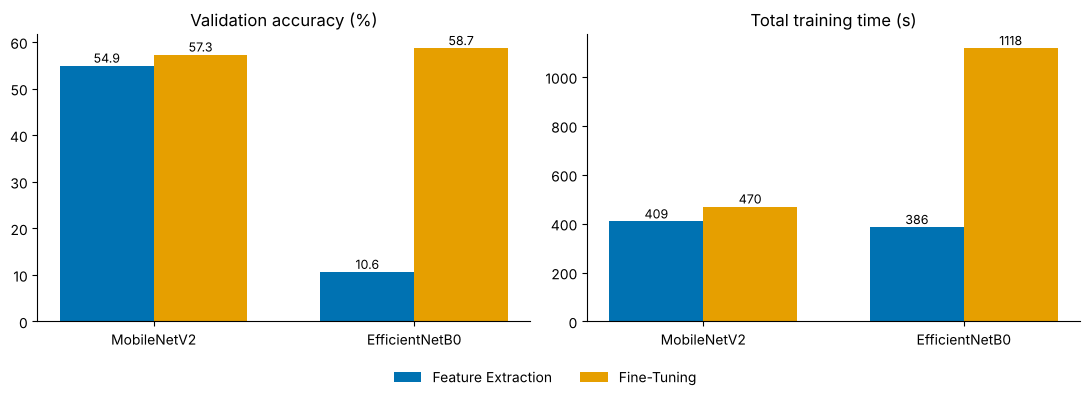

In [3]:
#-- Accuracy and training-time comparison. --#
import numpy as np
import matplotlib.pyplot as plt

COLORS = {"Feature Extraction": "#0072B2", "Fine-Tuning": "#E69F00"}
done = [m for m in RESULTS if all(RESULTS[m].values())]   #-- models with both approaches finished --#
x = np.arange(len(done))
w = 0.36

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, title, fmt, scale in [
    (axes[0], "val_acc", "Validation accuracy (%)", "{:.1f}", 100),
    (axes[1], "time_s", "Total training time (s)", "{:.0f}", 1),
]:
    for k, approach in enumerate(["Feature Extraction", "Fine-Tuning"]):
        vals = [RESULTS[m][approach][key] * scale for m in done]
        bars = ax.bar(x + (k - 0.5) * w, vals, w, label=approach, color=COLORS[approach])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(done)
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## 5.3 Validation-accuracy curves. ##

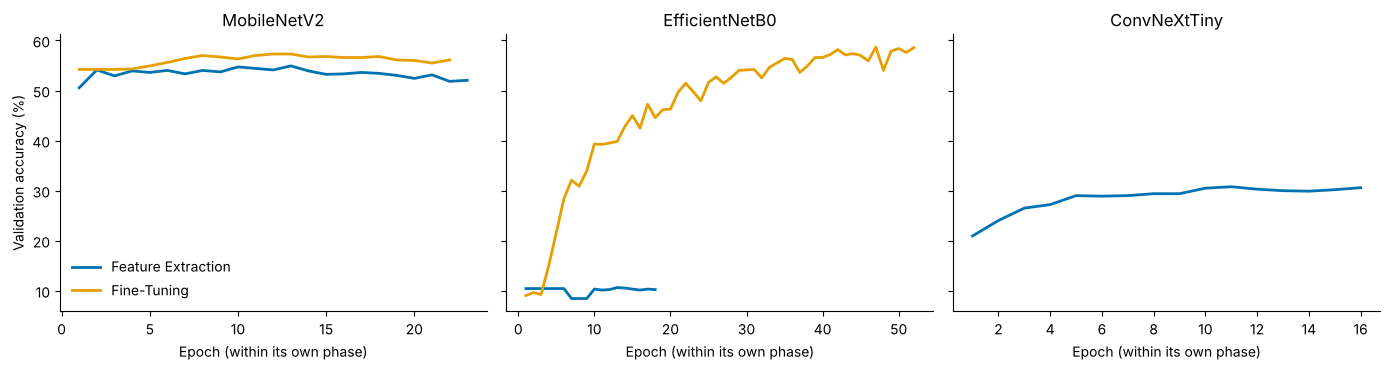

In [4]:
#-- Validation-accuracy curves per epoch (recorded from the logs). --#
VAL_ACC_HISTORY = {
    ("MobileNetV2", "Feature Extraction"): [0.5055,0.5412,0.5293,0.5392,0.5362,0.5402,0.5333,0.5402,0.5372,0.5472,0.5442,0.5412,0.5492,0.5392,0.5323,0.5333,0.5362,0.5343,0.5303,0.5243,0.5313,0.5184,0.5204],
    ("MobileNetV2", "Fine-Tuning"):        [0.5422,0.5422,0.5422,0.5432,0.5492,0.5561,0.5641,0.57,0.567,0.5631,0.57,0.573,0.573,0.567,0.568,0.566,0.566,0.568,0.5611,0.5601,0.5551,0.5611],
    ("EfficientNetB0", "Feature Extraction"): [0.1043,0.1043,0.1043,0.1043,0.1043,0.1043,0.0844,0.0844,0.0844,0.1033,0.1013,0.1023,0.1063,0.1053,0.1033,0.1013,0.1033,0.1023],
    ("EfficientNetB0", "Fine-Tuning"):        [0.0904,0.0963,0.0924,0.15,0.2165,0.284,0.3208,0.3088,0.3396,0.3932,0.3923,0.3952,0.3982,0.428,0.4499,0.425,0.4727,0.4459,0.4618,0.4628,0.4965,0.5144,0.4975,0.4796,0.5164,0.5273,0.5144,0.5263,0.5402,0.5412,0.5422,0.5253,0.5462,0.5551,0.5641,0.5621,0.5362,0.5492,0.566,0.566,0.572,0.5819,0.571,0.574,0.57,0.5591,0.5869,0.5402,0.5789,0.5839,0.576,0.5859],
    ("ConvNeXtTiny", "Feature Extraction"):   [0.2095,0.2403,0.2651,0.2721,0.29,0.289,0.29,0.2939,0.2939,0.3049,0.3078,0.3029,0.2999,0.2989,0.3019,0.3059],
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, model in zip(axes, ["MobileNetV2", "EfficientNetB0", "ConvNeXtTiny"]):
    for approach in ["Feature Extraction", "Fine-Tuning"]:
        h = VAL_ACC_HISTORY.get((model, approach))
        if h:
            ax.plot(range(1, len(h) + 1), np.array(h) * 100, label=approach, color=COLORS[approach], lw=2)
    ax.set_title(model)
    ax.set_xlabel("Epoch (within its own phase)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Validation accuracy (%)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

## 5.4 Model architecture diagram. ##

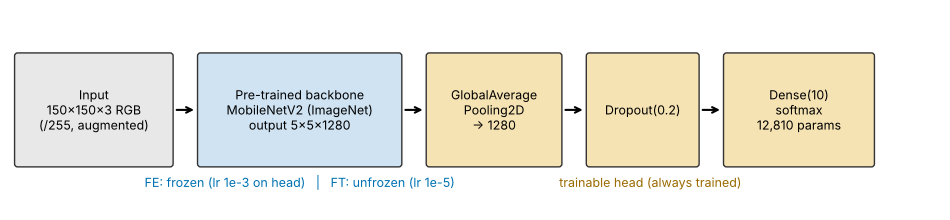

In [5]:
#-- Architecture diagram of the transfer-learning model (same head for all three backbones). --#
from matplotlib.patches import FancyBboxPatch

stages = [
    ("Input\n150x150x3 RGB\n(/255, augmented)", "#E8E8E8"),
    ("Pre-trained backbone\nMobileNetV2 (ImageNet)\noutput 5x5x1280", "#CFE3F3"),
    ("GlobalAverage\nPooling2D\n-> 1280", "#F6E3B4"),
    ("Dropout(0.2)", "#F6E3B4"),
    ("Dense(10)\nsoftmax\n12,810 params", "#F6E3B4"),
]
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.axis("off"); ax.set_xlim(0, 12.2); ax.set_ylim(0, 2.6)
xs = [0.1, 2.5, 5.5, 7.6, 9.4]; ws = [2.0, 2.6, 1.7, 1.4, 1.9]
for (label, color), x0, w0 in zip(stages, xs, ws):
    ax.add_patch(FancyBboxPatch((x0, 0.6), w0, 1.4, boxstyle="round,pad=0.04", fc=color, ec="#333"))
    ax.text(x0 + w0 / 2, 1.3, label, ha="center", va="center", fontsize=9)
for k in range(len(xs) - 1):
    ax.annotate("", xy=(xs[k + 1] - 0.05, 1.3), xytext=(xs[k] + ws[k] + 0.05, 1.3), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(xs[1] + ws[1] / 2, 0.3, "FE: frozen (lr 1e-3 on head)   |   FT: unfrozen (lr 1e-5)", ha="center", fontsize=9, color="#0072B2")
ax.text((xs[2] + xs[4] + ws[4]) / 2, 0.3, "trainable head (always trained)", ha="center", fontsize=9, color="#9a6a00")
plt.show()

## Conclusions ##

**Accuracy.** Fine-tuning gave the best validation accuracy for every backbone that was fine-tuned: MobileNetV2 improved from 54.92% to 57.30% (+2.4 pts) and EfficientNetB0 from 10.63% to 58.69%. Fine-tuning also fits the training set much more strongly (MobileNetV2 train accuracy 61% -> 72% at the best epoch, up to ~80% by the end) while validation accuracy plateaus around 57-59%, so the gap between train and validation widens (overfitting on only ~4,000 training images).

**Training time.** Feature extraction is cheaper per epoch (MobileNetV2 17.8 s vs 21.4 s) because the frozen base needs no weight updates. In total, MobileNetV2 needed 409 s (FE) vs 470 s (FT), i.e. about 15% more for +2.4 pts. EfficientNetB0 fine-tuning took 1,118 s because it needed 52 epochs to recover.

**Caveats (read before trusting the EfficientNetB0 / ConvNeXtTiny numbers).**

1. The data pipeline divides pixels by 255 (cell 20), but `EfficientNetB0` and `ConvNeXtTiny` in Keras already contain their own preprocessing and expect raw 0-255 pixels, so they receive a double-scaled, almost-constant input. This is the most likely reason the frozen EfficientNetB0 stays at ~10% (the majority-class rate) and frozen ConvNeXtTiny reaches only ~31%; fine-tuning can re-learn the first layers, which is why EfficientNetB0 FT "recovers" to 58.7%. Their FE-vs-FT gap therefore mostly reflects this input mismatch, not the normal behaviour of the two methods. MobileNetV2 (expects [-1, 1], receives [0, 1]) is only mildly affected, so it gives the cleanest FE-vs-FT comparison.
2. Fine-tuning here unfreezes the **whole** base model. The lab text says to unfreeze *some of the top layers*; to follow it exactly, set `base_model.trainable = True` and then freeze all but the last ~30 layers (`for layer in base_model.layers[:-30]: layer.trainable = False`) before re-compiling.
3. ConvNeXtTiny fine-tuning (cell 41) failed with `NameError` because the runtime was reset; re-run cells 39-41 and fill in `RESULTS["ConvNeXtTiny"]["Fine-Tuning"]`.
4. The dataset on Drive contains 5,036 labelled images (4,029 train / 1,007 validation), not the 10,000 mentioned in the lab sheet. The cell `Estimated Accuracy` in 4.2 is the mean softmax confidence on the unlabeled test set, not a real accuracy.